# Climate Injustice: Quantifying the Gap Between Carbon Contributors and Climate Victims

**Data:** EDGAR GHG emissions 1970–2023 (EU Joint Research Centre) · ND-GAIN Country Index 2026 (University of Notre Dame)

> *The countries that caused climate change are not the countries that will suffer most from it.* — this notebook tests that sentence with data.

| # | Chapter | Question | Concepts used |
|---|---|---|---|
| 1 | The data | What do we have? | loading, cleaning, merging, mean vs median, log |
| 2 | The contributors | Who emitted the carbon? | totals, shares, ranking |
| 3 | The victims | Who is most vulnerable? | sorting, mean |
| 4 | The gap | How unequal is it? | quartiles (percentiles), shares |
| 5 | The relationship | Do emitters suffer less? | Pearson r, Spearman ρ, least-squares line, R² |
| 6 | The comparison | How different are rich and poor countries? | mean, median, SD, IQR, z-score, box plot, conditional probability, lift |
| 7 | The groups | What kinds of countries exist? | z-score, K-Means (Euclidean distance), elbow method |
| 8 | The prediction | Can emissions alone spot a victim? | decision tree, Gini index, Gini gain, accuracy, precision, recall, F1 |
| 9 | The bill | Who owes the climate debt? | climate-debt index |

## 0. Setup

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

os.makedirs('figures', exist_ok=True)
RESULTS = {}                      # key numbers, used later to write the report

EMIT, VICT = '#eb6834', '#2a78d6'  # orange = emitters, blue = victims / people
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False})

def save(fig, name):
    fig.savefig(f'figures/{name}.png', bbox_inches='tight', facecolor='white')

## Chapter 1 — The data
| Dataset | Measures | Unit |
|---|---|---|
| EDGAR, sheet *TOTALS BY COUNTRY* | yearly greenhouse-gas emissions of each country, 1970–2023 | Gg CO₂-equivalent (1 Gg = 1,000 t) |
| ND-GAIN `vulnerability.csv` | how exposed and sensitive a country is to climate change | 0 (safe) → 1 (very vulnerable) |
| ND-GAIN `readiness.csv` | how able a country is to adapt (economy, governance, society) | 0 (not ready) → 1 (very ready) |
| ND-GAIN `pop`, `gdp` | population and GDP per person | persons, US$ |

In [2]:
edgar = pd.read_excel('EDGAR_AR5_GHG_1970_2023/EDGAR_AR5_GHG_1970_2023.xlsx',
                      sheet_name='TOTALS BY COUNTRY', skiprows=9)      # first 9 rows are notes
YEARS = [c for c in edgar.columns if str(c).startswith('Y_')]
print(edgar.shape)
edgar.head()

(225, 59)


,IPCC_annex,C_group_IM24_sh,Country_code_A3,Name,Substance,Y_1970,Y_1971,Y_1972,Y_1973,Y_1974,...,Y_2014,Y_2015,Y_2016,Y_2017,Y_2018,Y_2019,Y_2020,Y_2021,Y_2022,Y_2023
0,Non-Annex_I,Rest Central America,ABW,Aruba,GWP_100_AR5_GHG,36.713033,41.538132,52.390750,57.359887,56.630192,...,469.468414,490.990250,514.539464,496.140535,495.531919,588.997896,482.159941,531.201512,533.603088,561.497605
1,Non-Annex_I,India +,AFG,Afghanistan,GWP_100_AR5_GHG,15437.430263,15364.077308,13316.628180,13934.875093,15177.862417,...,27420.132302,27408.331772,26633.998536,27691.927104,27553.281612,26982.776572,26646.320070,27643.074355,28614.071224,29460.052110
2,Non-Annex_I,Southern_Africa,AGO,Angola,GWP_100_AR5_GHG,18998.762967,18866.057085,21459.002495,23018.940660,23685.423333,...,77295.699295,81775.030635,78875.889482,73424.409437,69504.638320,69910.831904,61680.081008,64408.994317,67210.841707,67700.756248
3,Non-Annex_I,Rest Central America,AIA,Anguilla,GWP_100_AR5_GHG,3.355052,3.395956,3.533699,3.411377,3.694243,...,31.209941,31.334184,31.728472,32.475516,31.594224,30.947736,26.037062,25.224274,25.068398,26.210752
4,Int. Aviation,Int. Aviation,AIR,Int. Aviation,GWP_100_AR5_GHG,172478.021013,172465.451921,182459.818548,190296.909848,183162.103533,...,514263.976095,543354.254566,567631.286648,597771.580137,624135.612321,633464.501865,302632.336740,335728.729280,416953.421848,498178.114415


In [3]:
G = 'nd_gain_country_index_2026_release_data_v2/resources 2/'
vul   = pd.read_csv(G + 'vulnerability/vulnerability.csv', index_col='ISO3')
ready = pd.read_csv(G + 'readiness/readiness.csv', index_col='ISO3')
pop   = pd.read_csv(G + 'indicators/pop/raw.csv', index_col='ISO3')
gdp   = pd.read_csv(G + 'indicators/gdp/input.csv', index_col='ISO3')
print(vul.shape, ready.shape, pop.shape, gdp.shape)
vul.head()

(192, 31) (192, 31) (192, 31) (192, 31)


,Name,1995,1996,1997,1998,1999,2000,2001,2002,2003,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
ISO3,,,,,,,,,,,,,,,,,,,,,
AFG,Afghanistan,0.648095,0.648263,0.648422,0.646764,0.645413,0.643984,0.642144,0.640003,0.630012,...,0.617664,0.618918,0.624045,0.621220,0.616650,0.610147,0.612746,0.613643,0.612285,0.611631
ALB,Albania,0.504738,0.503647,0.501314,0.502447,0.507859,0.506091,0.507571,0.505339,0.503695,...,0.452182,0.453082,0.454817,0.445777,0.439419,0.432775,0.420492,0.414842,0.413696,0.416323
DZA,Algeria,0.471356,0.470388,0.469082,0.465994,0.463304,0.461794,0.462872,0.465395,0.461544,...,0.448650,0.448086,0.450025,0.451836,0.454772,0.431743,0.432066,0.430264,0.429950,0.429884
AND,Andorra,0.451455,0.451377,0.451477,0.443372,0.441003,0.414000,0.412188,0.408647,0.404555,...,0.357917,0.354835,0.353776,0.352272,0.352558,0.349698,0.350660,0.349690,0.350520,0.350781
AGO,Angola,0.516244,0.516593,0.516494,0.516396,0.516510,0.516753,0.519123,0.517334,0.516961,...,0.524903,0.526534,0.527919,0.530669,0.530218,0.532386,0.528720,0.526649,0.527345,0.527907


### 1.1 Cleaning and merging
* Keep only real countries (drop the *Int. Aviation* and *Int. Shipping* rows).
* Join the two sources on the 3-letter country code (ISO3). Use **2023**, the latest year in both.
* Convert Gg → Mt (÷ 1,000).

In [4]:
countries = edgar[edgar['IPCC_annex'].isin(['Annex_I', 'Non-Annex_I'])].set_index('Country_code_A3')

df = pd.DataFrame({'country': vul['Name'], 'vulnerability': vul['2023'], 'readiness': ready['2023'],
                   'population': pop['2023'], 'gdp_pc': gdp['2023']})
df = df.join(countries[['IPCC_annex']], how='inner')
df['emis_2023_mt'] = countries['Y_2023'] / 1000
df['emis_2000_mt'] = countries['Y_2000'] / 1000
df['cum_mt']       = countries[YEARS].sum(axis=1) / 1000        # total 1970-2023
df = df.dropna(subset=['vulnerability', 'readiness', 'population'])

df['country'] = df['country'].replace({'Congo, the Democratic Republic o': 'DR Congo', 'Russian Federation': 'Russia',
    'Tanzania, United Republic of': 'Tanzania', 'Iran, Islamic Republic of': 'Iran',
    'Micronesia, Federated States of': 'Micronesia', 'Korea, Republic of': 'South Korea'})
RESULTS['n_countries'] = len(df)
print('Countries in both datasets:', len(df))

Countries in both datasets: 186


### 1.2 New features
| Feature | Formula |
|---|---|
| `pc_2023` | emissions 2023 ÷ population (tonnes per person) |
| `cum_pc` | emissions 1970–2023 ÷ population (historical tonnes per person) |
| `growth` | emissions 2023 ÷ emissions 2000 − 1 |
| `share_cum`, `share_pop` | country ÷ world total × 100 |
| `climate_debt` | `share_cum − share_pop` (> 0 = used more than its fair share) |

In [5]:
df['pc_2023']      = df['emis_2023_mt'] * 1e6 / df['population']
df['cum_pc']       = df['cum_mt'] * 1e6 / df['population']
df['growth']       = df['emis_2023_mt'] / df['emis_2000_mt'] - 1
df['share_cum']    = df['cum_mt'] / df['cum_mt'].sum() * 100
df['share_pop']    = df['population'] / df['population'].sum() * 100
df['climate_debt'] = df['share_cum'] - df['share_pop']
df.to_csv('climate_injustice_dataset.csv')
df[['country', 'IPCC_annex', 'vulnerability', 'readiness', 'pc_2023', 'cum_pc']].head()

,country,IPCC_annex,vulnerability,readiness,pc_2023,cum_pc
AFG,Afghanistan,Non-Annex_I,0.612285,0.273456,0.710655,23.566318
ALB,Albania,Non-Annex_I,0.413696,0.454449,3.178695,203.787086
DZA,Algeria,Non-Annex_I,0.429950,0.375295,5.562579,183.215249
AGO,Angola,Non-Annex_I,0.527345,0.257770,1.842202,71.954244
ATG,Antigua and Barbuda,Non-Annex_I,0.482785,0.440443,4.163875,153.274569


### 1.3 Exploring the data

In [6]:
df[['vulnerability', 'readiness', 'pc_2023', 'cum_pc', 'gdp_pc']].describe().round(2)

,vulnerability,readiness,pc_2023,cum_pc,gdp_pc
count,186.00,186.00,186.00,186.00,184.00
mean,0.45,0.41,6.65,307.28,27687.42
std,0.09,0.14,9.33,525.35,28720.00
min,0.26,0.15,0.07,2.93,1149.98
25%,0.38,0.30,1.90,64.55,6275.53
50%,0.45,0.38,4.22,151.96,17614.92
75%,0.51,0.49,7.93,437.11,42609.93
max,0.66,0.74,84.71,6269.71,150508.22


Emissions per person: mean = 6.65 t, median = 4.22 t


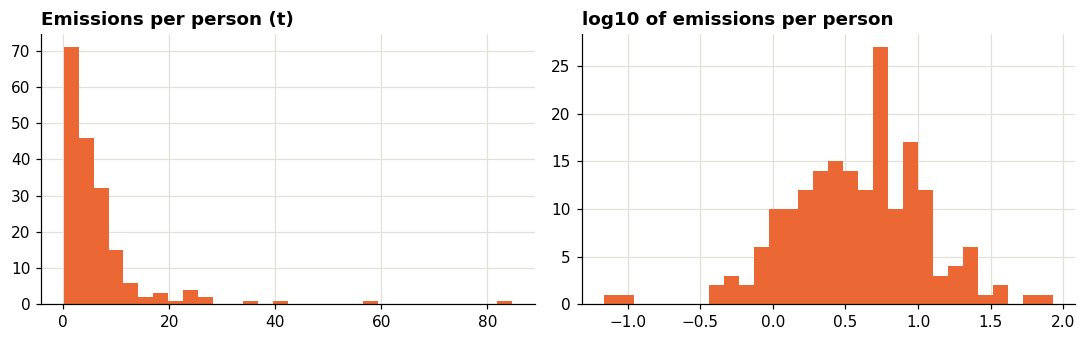

In [7]:
RESULTS['mean_pc'], RESULTS['median_pc'] = df['pc_2023'].mean(), df['pc_2023'].median()
print(f"Emissions per person: mean = {RESULTS['mean_pc']:.2f} t, median = {RESULTS['median_pc']:.2f} t")

df['log_pc']     = np.log10(df['pc_2023'])
df['log_cum_pc'] = np.log10(df['cum_pc'])
df['log_gdp']    = np.log10(df['gdp_pc'])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(df['pc_2023'], bins=30, color=EMIT); ax[0].set_title('Emissions per person (t)')
ax[1].hist(df['log_pc'], bins=30, color=EMIT);  ax[1].set_title('log10 of emissions per person')
plt.tight_layout(); plt.show()

The mean (6.6 t) is much bigger than the median (4.2 t): a few oil states and small islands emit a lot, so the data is
**right-skewed**. Taking **log10** spreads the values out evenly, so log values are used for the line fit and the clusters.

## Chapter 2 — The contributors: who emitted the carbon?

Annex I: 16.8% of people, 47.2% of emissions since 1970


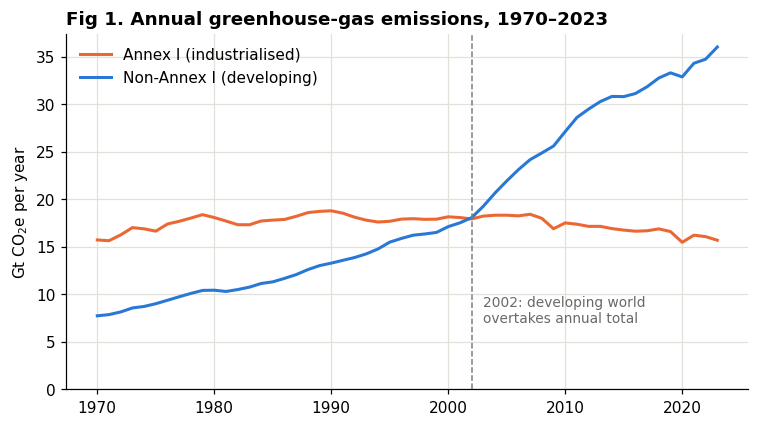

In [8]:
annual = edgar.groupby('IPCC_annex')[YEARS].sum().T / 1e6           # Gg -> Gt
annual.index = [int(y[2:]) for y in annual.index]
annual['World'] = annual.sum(axis=1)
cross = annual.index[annual['Non-Annex_I'] > annual['Annex_I']][0]  # first year developing > industrialised

RESULTS.update({'world_1970_gt': annual.loc[1970, 'World'], 'world_2023_gt': annual.loc[2023, 'World'],
                'nonannex_1970_gt': annual.loc[1970, 'Non-Annex_I'], 'nonannex_2023_gt': annual.loc[2023, 'Non-Annex_I'],
                'crossover_year': int(cross),
                'annex_cum_share': annual['Annex_I'].sum() / annual['World'].sum() * 100,
                'annex_pop_share': df.loc[df.IPCC_annex == 'Annex_I', 'share_pop'].sum(),
                'annual_points': annual.loc[[1970, 1980, 1990, 2000, 2010, 2020, 2023], ['Annex_I', 'Non-Annex_I']].round(1).to_dict('index')})
print(f"Annex I: {RESULTS['annex_pop_share']:.1f}% of people, {RESULTS['annex_cum_share']:.1f}% of emissions since 1970")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(annual.index, annual['Annex_I'], color=EMIT, lw=2, label='Annex I (industrialised)')
ax.plot(annual.index, annual['Non-Annex_I'], color=VICT, lw=2, label='Non-Annex I (developing)')
ax.axvline(cross, color='grey', lw=1, ls='--')
ax.text(cross + 1, 7, f'{cross}: developing world\novertakes annual total', fontsize=9, color='dimgrey')
ax.set(title='Fig 1. Annual greenhouse-gas emissions, 1970–2023', ylabel='Gt CO$_2$e per year', ylim=(0, None))
ax.legend(loc='upper left')
save(fig, 'fig1_trend'); plt.show()

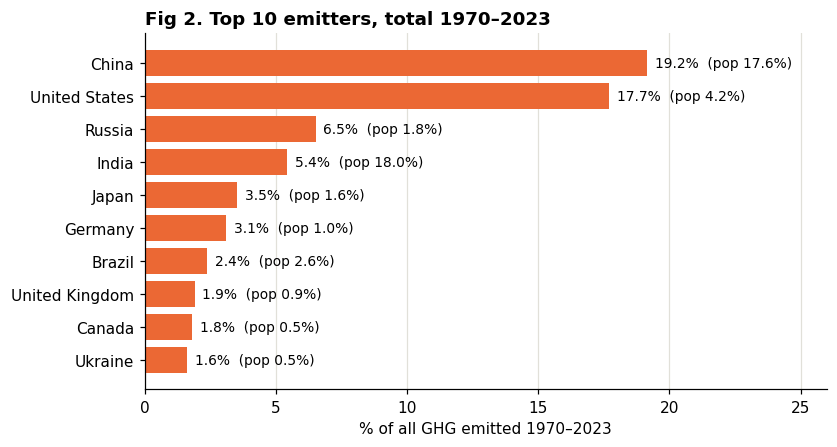

Top 10 together: 63.1% of all emissions


In [9]:
top10 = df.sort_values('cum_mt', ascending=False).head(10)
RESULTS['top10'] = top10[['country', 'share_cum', 'share_pop']].round(1).values.tolist()
RESULTS['top10_cum_share'] = top10['share_cum'].sum()
RESULTS['us_cum_pc'] = df.loc['USA', 'cum_pc']

fig, ax = plt.subplots(figsize=(8, 4.2))
t = top10.iloc[::-1]
ax.barh(t['country'], t['share_cum'], color=EMIT)
for y, (v, p) in enumerate(zip(t['share_cum'], t['share_pop'])):
    ax.text(v + 0.3, y, f'{v:.1f}%  (pop {p:.1f}%)', va='center', fontsize=9)
ax.set(title='Fig 2. Top 10 emitters, total 1970–2023', xlabel='% of all GHG emitted 1970–2023', xlim=(0, 26))
ax.grid(axis='y', visible=False)
save(fig, 'fig2_top10'); plt.show()
print(f"Top 10 together: {RESULTS['top10_cum_share']:.1f}% of all emissions")

**Takeaway:** developing countries emit more *each year* now, but the carbon already in the sky came mostly from a few rich countries.

## Chapter 3 — The victims: who is most vulnerable?

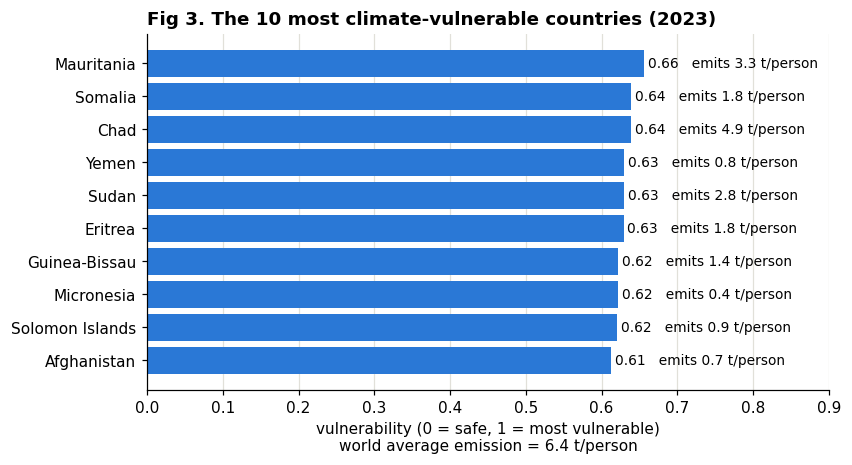

These 10 countries emitted 0.57% of all emissions since 1970


In [10]:
top_vul = df.sort_values('vulnerability', ascending=False).head(10)
RESULTS['top_vul'] = top_vul[['country', 'vulnerability', 'readiness', 'pc_2023']].round(3).values.tolist()
RESULTS['top_vul_pc_mean'] = top_vul['pc_2023'].mean()
RESULTS['top_vul_cum_share'] = top_vul['share_cum'].sum()
RESULTS['world_pc'] = df['emis_2023_mt'].sum() * 1e6 / df['population'].sum()

fig, ax = plt.subplots(figsize=(8, 4.2))
t = top_vul.iloc[::-1]
ax.barh(t['country'], t['vulnerability'], color=VICT)
for y, (v, pc) in enumerate(zip(t['vulnerability'], t['pc_2023'])):
    ax.text(v + 0.005, y, f'{v:.2f}   emits {pc:.1f} t/person', va='center', fontsize=9)
ax.set(title='Fig 3. The 10 most climate-vulnerable countries (2023)', xlim=(0, 0.9),
       xlabel=f"vulnerability (0 = safe, 1 = most vulnerable)\nworld average emission = {RESULTS['world_pc']:.1f} t/person")
ax.grid(axis='y', visible=False)
save(fig, 'fig3_top_vulnerable'); plt.show()
print(f"These 10 countries emitted {RESULTS['top_vul_cum_share']:.2f}% of all emissions since 1970")

## Chapter 4 — The gap: how unequal is it?
Split the countries into **4 equal groups (quartiles)** by vulnerability, using the 25th, 50th and 75th percentiles.
Compare each group's share of emissions with its share of people. In a fair world the two bars would be equal.

           share_cum  share_pop
vul_group                      
Q1 least        51.1       19.6
Q2              34.0       33.5
Q3              11.5       31.2
Q4 most          3.4       15.7


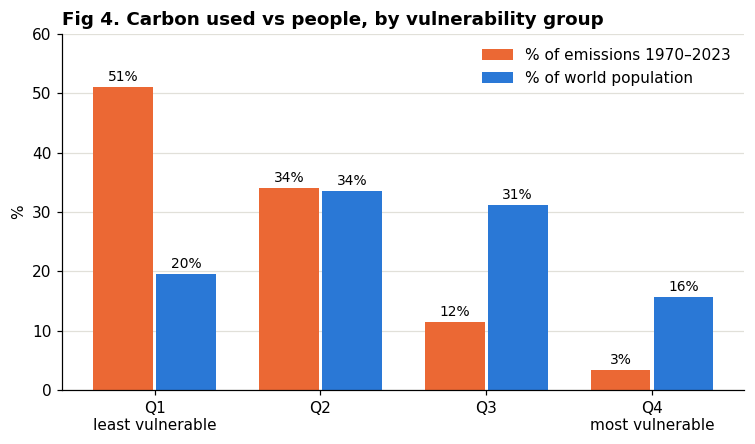

In [11]:
df['vul_group'] = pd.qcut(df['vulnerability'], 4, labels=['Q1 least', 'Q2', 'Q3', 'Q4 most'])
q = df.groupby('vul_group', observed=True)[['share_cum', 'share_pop']].sum()
print(q.round(1))
RESULTS['quartiles'] = {k.split()[0]: v for k, v in q.to_dict('index').items()}

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(4)
ax.bar(x - 0.19, q['share_cum'], 0.36, color=EMIT, label='% of emissions 1970–2023')
ax.bar(x + 0.19, q['share_pop'], 0.36, color=VICT, label='% of world population')
for i in range(4):
    ax.text(i - 0.19, q['share_cum'].iloc[i] + 1, f"{q['share_cum'].iloc[i]:.0f}%", ha='center', fontsize=9)
    ax.text(i + 0.19, q['share_pop'].iloc[i] + 1, f"{q['share_pop'].iloc[i]:.0f}%", ha='center', fontsize=9)
ax.set_xticks(x, ['Q1\nleast vulnerable', 'Q2', 'Q3', 'Q4\nmost vulnerable'])
ax.set(title='Fig 4. Carbon used vs people, by vulnerability group', ylabel='%', ylim=(0, 60))
ax.legend(); ax.grid(axis='x', visible=False)
save(fig, 'fig4_quartiles'); plt.show()

In [12]:
# Sort countries from lowest to highest emitter per person, then add up people and emissions
s = df.sort_values('cum_pc')
cum_people = s['share_pop'].cumsum()
RESULTS['bottom50_share'] = s.loc[cum_people <= 50, 'share_cum'].sum()
RESULTS['top10pct_share'] = s.loc[cum_people > 90, 'share_cum'].sum()
print(f"The lowest-emitting half of humanity produced {RESULTS['bottom50_share']:.1f}% of all emissions")
print(f"The highest-emitting tenth of humanity produced {RESULTS['top10pct_share']:.1f}%")

The lowest-emitting half of humanity produced 12.4% of all emissions
The highest-emitting tenth of humanity produced 37.8%


## Chapter 5 — The relationship: do emitters suffer less?
* **Pearson r** measures how close the points are to a straight line (−1 to +1).
* **Spearman ρ** is Pearson r computed on the *ranks*: ρ = 1 − 6Σd² / n(n²−1). It is not affected by extreme values.
* **Least-squares line:** vulnerability = a + b × log10(emissions per person), with b = Sxy / Sxx and a = ȳ − b·x̄.
* **R² = 1 − SSE / Syy**: the share of the variation in vulnerability explained by the line.

In [13]:
x, y = df['log_pc'], df['vulnerability']
r = np.corrcoef(x, y)[0, 1]
rho = x.rank().corr(y.rank())                        # Spearman = Pearson on ranks

b = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
a = y.mean() - b * x.mean()
sse = ((y - (a + b * x)) ** 2).sum()
r2 = 1 - sse / ((y - y.mean()) ** 2).sum()

RESULTS.update({'r_pc': r, 'rho_pc': rho, 'reg_a': a, 'reg_b': b, 'reg_r2': r2,
                'r_pc_readiness': np.corrcoef(x, df['readiness'])[0, 1]})
print(f"Pearson r = {r:.3f}, Spearman rho = {rho:.3f}")
print(f"Line: vulnerability = {a:.3f} + ({b:.3f}) x log10(emissions per person),   R^2 = {r2:.3f}")

Pearson r = -0.621, Spearman rho = -0.708
Line: vulnerability = 0.521 + (-0.120) x log10(emissions per person),   R^2 = 0.385


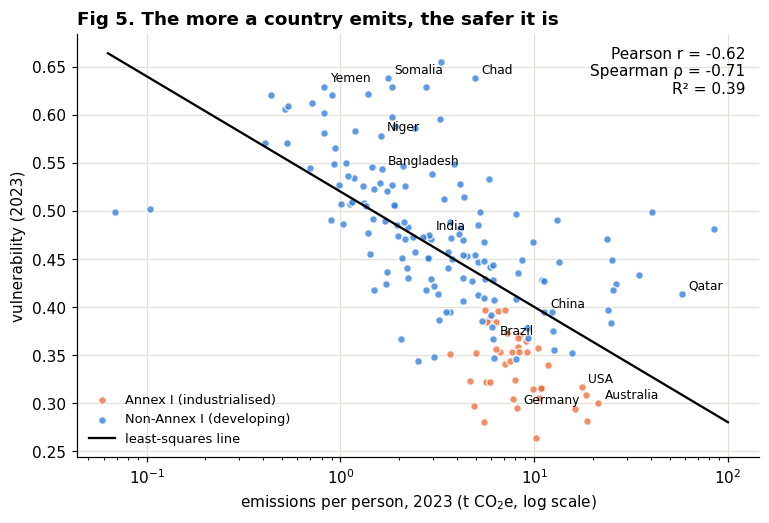

In [14]:
label = ['USA', 'QAT', 'AUS', 'CHN', 'DEU', 'IND', 'BRA', 'SOM', 'TCD', 'BGD', 'NER', 'YEM']
fig, ax = plt.subplots(figsize=(8, 5))
for grp, c, name in [('Annex_I', EMIT, 'Annex I (industrialised)'), ('Non-Annex_I', VICT, 'Non-Annex I (developing)')]:
    d = df[df.IPCC_annex == grp]
    ax.scatter(d['pc_2023'], d['vulnerability'], s=25, color=c, alpha=0.75, edgecolor='white', label=name)
xs = np.logspace(-1.2, 2, 50)
ax.plot(xs, a + b * np.log10(xs), color='black', lw=1.5, label='least-squares line')
for iso in label:
    ax.annotate(df.loc[iso, 'country'].replace('United States', 'USA'), (df.loc[iso, 'pc_2023'], df.loc[iso, 'vulnerability']),
                xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set(title='Fig 5. The more a country emits, the safer it is',
       xlabel='emissions per person, 2023 (t CO$_2$e, log scale)', ylabel='vulnerability (2023)')
ax.text(0.98, 0.97, f'Pearson r = {r:.2f}\nSpearman ρ = {rho:.2f}\nR² = {r2:.2f}', transform=ax.transAxes, ha='right', va='top')
ax.legend(loc='lower left', fontsize=8.5)
save(fig, 'fig5_scatter'); plt.show()
RESULTS['scatter_points'] = df.loc[label, ['country', 'IPCC_annex', 'pc_2023', 'vulnerability']].round(3).values.tolist()

**Is it emissions, or is it money?** Rich countries emit more *and* can afford protection. Compare the R² of two
least-squares lines and the correlation between emissions and GDP.

R^2 using emissions: 0.39   R^2 using GDP: 0.70
Pearson r between emissions and GDP: 0.76


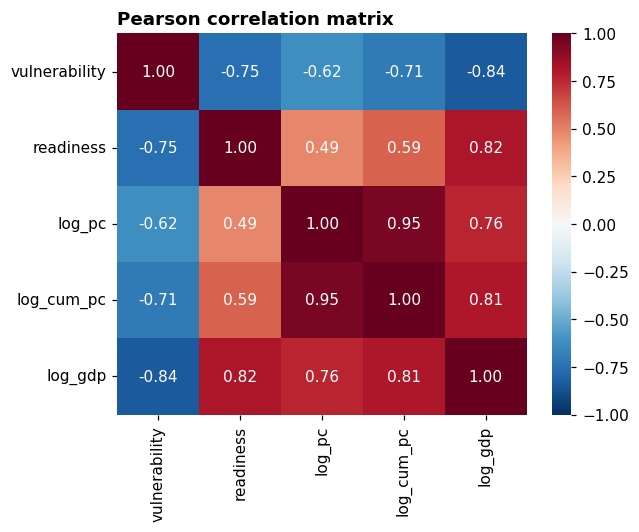

In [15]:
d = df.dropna(subset=['log_gdp'])
def line_r2(x, y):
    b, a = np.polyfit(x, y, 1)                       # least-squares line
    return 1 - ((y - (a + b * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()

RESULTS['r2_gdp'] = line_r2(d['log_gdp'], d['vulnerability'])
RESULTS['r_gdp_vul'] = np.corrcoef(d['log_gdp'], d['vulnerability'])[0, 1]
RESULTS['r_pc_gdp'] = np.corrcoef(d['log_pc'], d['log_gdp'])[0, 1]
print(f"R^2 using emissions: {RESULTS['reg_r2']:.2f}   R^2 using GDP: {RESULTS['r2_gdp']:.2f}")
print(f"Pearson r between emissions and GDP: {RESULTS['r_pc_gdp']:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[['vulnerability', 'readiness', 'log_pc', 'log_cum_pc', 'log_gdp']].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Pearson correlation matrix'); plt.show()

**Takeaway:** strong negative link between emissions and vulnerability. GDP explains vulnerability even better, and GDP and
emissions move together — **wealth drives both**. Emitting does not make a country safe; the fossil-fuelled growth that
created the emissions also paid for protection.

## Chapter 6 — The comparison: industrialised vs developing countries
Describe each group with **mean, median, standard deviation, quartiles and IQR**, and use **z-scores**
(z = (x − mean) / SD) to see how far each group sits from the world average.

             count   mean    std    min    25%    50%    75%    max    IQR  \
IPCC_annex                                                                   
Annex_I       40.0  0.338  0.035  0.264  0.313  0.343  0.361  0.397  0.048   
Non-Annex_I  146.0  0.481  0.074  0.344  0.428  0.473  0.528  0.656  0.099   

             mean z-score  
IPCC_annex                 
Annex_I            -1.251  
Non-Annex_I         0.343  
86% of developing countries are more vulnerable than the MOST vulnerable rich country


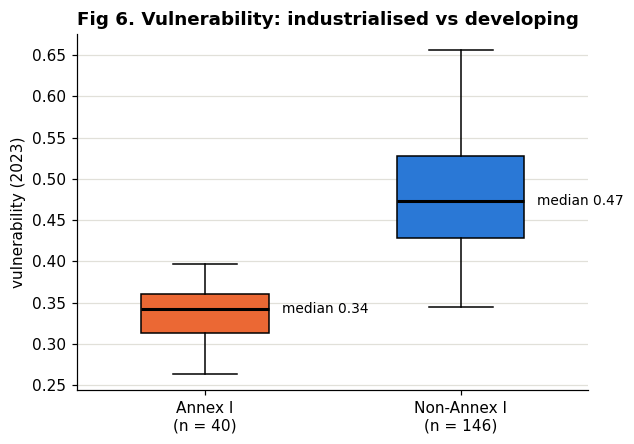

In [16]:
df['vul_z'] = (df['vulnerability'] - df['vulnerability'].mean()) / df['vulnerability'].std()
summary = df.groupby('IPCC_annex')['vulnerability'].describe()
summary['IQR'] = summary['75%'] - summary['25%']
summary['mean z-score'] = df.groupby('IPCC_annex')['vul_z'].mean()
print(summary.round(3))

annex, non = df[df.IPCC_annex == 'Annex_I'], df[df.IPCC_annex == 'Non-Annex_I']
RESULTS['groups'] = summary.round(4).to_dict('index')
RESULTS['share_non_above_annex_max'] = (non['vulnerability'] > annex['vulnerability'].max()).mean() * 100
print(f"{RESULTS['share_non_above_annex_max']:.0f}% of developing countries are more vulnerable than the MOST vulnerable rich country")

fig, ax = plt.subplots(figsize=(6, 4.2))
bp = ax.boxplot([annex['vulnerability'], non['vulnerability']], widths=0.5, patch_artist=True,
                medianprops=dict(color='black', lw=2))
for box, c in zip(bp['boxes'], [EMIT, VICT]):
    box.set_facecolor(c)
ax.set_xticks([1, 2], [f'Annex I\n(n = {len(annex)})', f'Non-Annex I\n(n = {len(non)})'])
for i, m in enumerate([annex['vulnerability'].median(), non['vulnerability'].median()], start=1):
    ax.text(i + 0.3, m, f'median {m:.2f}', va='center', fontsize=9)
ax.set(title='Fig 6. Vulnerability: industrialised vs developing', ylabel='vulnerability (2023)')
ax.grid(axis='x', visible=False)
save(fig, 'fig6_boxplot'); plt.show()

**Conditional probability and lift.** A country is called a **climate victim** if its vulnerability is above the median
**and** its readiness is below the median. Then:
* P(victim | Annex I) and P(victim | Non-Annex I)
* Rule {Non-Annex I} ⇒ {victim}: support, confidence and **lift = confidence / support(victim)** (lift > 1 means the two go together)

In [17]:
df['victim'] = ((df['vulnerability'] > df['vulnerability'].median()) &
                (df['readiness'] < df['readiness'].median())).astype(int)
print(pd.crosstab(df['IPCC_annex'], df['victim'], margins=True))

N = len(df)
p_victim  = df['victim'].mean()
p_v_annex = df.loc[df.IPCC_annex == 'Annex_I', 'victim'].mean()
p_v_non   = df.loc[df.IPCC_annex == 'Non-Annex_I', 'victim'].mean()
support    = ((df.IPCC_annex == 'Non-Annex_I') & (df.victim == 1)).sum() / N
confidence = p_v_non
lift       = confidence / p_victim
RESULTS.update({'n_victims': int(df['victim'].sum()), 'n_annex': len(annex), 'n_non': len(non),
                'victims_non': int(df.loc[df.IPCC_annex == 'Non-Annex_I', 'victim'].sum()),
                'p_victim': p_victim, 'p_v_annex': p_v_annex, 'p_v_non': p_v_non,
                'support': support, 'confidence': confidence, 'lift': lift})
print(f"P(victim) = {p_victim:.3f} | P(victim | Annex I) = {p_v_annex:.3f} | P(victim | Non-Annex I) = {p_v_non:.3f}")
print(f"Rule Non-Annex I => victim: support = {support:.3f}, confidence = {confidence:.3f}, lift = {lift:.2f}")

victim         0   1  All
IPCC_annex               
Annex_I       40   0   40
Non-Annex_I   72  74  146
All          112  74  186
P(victim) = 0.398 | P(victim | Annex I) = 0.000 | P(victim | Non-Annex I) = 0.507
Rule Non-Annex I => victim: support = 0.398, confidence = 0.507, lift = 1.27


**Takeaway:** the two boxes do not even overlap — most developing countries are more vulnerable than the *most* vulnerable
rich country. No industrialised country is a climate victim; being a developing country raises the chance (lift > 1).

## Chapter 7 — The groups: K-Means clustering
Four features: log emissions per person, log historical emissions per person, vulnerability, readiness.
They are on different scales, so each is turned into a **z-score** first. K-Means then puts each country with the nearest
of k centres (Euclidean distance). The **elbow method** picks k: plot the inertia (sum of squared distances to the centres)
and choose the k where it stops falling quickly.

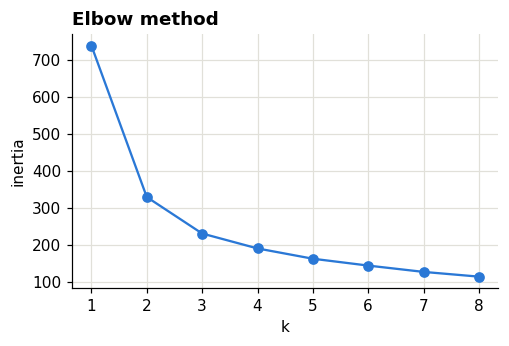

[740, 330, 231, 191, 163, 144, 127, 114]


In [18]:
FEATS = ['log_pc', 'log_cum_pc', 'vulnerability', 'readiness']
Z = (df[FEATS] - df[FEATS].mean()) / df[FEATS].std()        # z-scores

inertia = [KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z).inertia_ for k in range(1, 9)]
RESULTS['inertia'] = [round(v, 1) for v in inertia]
plt.figure(figsize=(5, 3))
plt.plot(range(1, 9), inertia, marker='o', color=VICT)
plt.title('Elbow method'); plt.xlabel('k'); plt.ylabel('inertia'); plt.show()
print([round(v) for v in inertia])

In [19]:
K = 4                                                     # the curve flattens after k = 4
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Z)
df['cluster_id'] = km.labels_

# name the clusters from least to most vulnerable
NAMES = ['Protected Polluters', 'Carbon-Heavy Middle', 'Emerging & Exposed', 'Frontline Victims']
order = df.groupby('cluster_id')['vulnerability'].mean().sort_values().index
df['cluster'] = df['cluster_id'].map({cid: NAMES[i] for i, cid in enumerate(order)})

prof = df.groupby('cluster').agg(countries=('country', 'size'), pop_share=('share_pop', 'sum'),
          emission_share=('share_cum', 'sum'), median_t_per_person=('pc_2023', 'median'),
          vulnerability=('vulnerability', 'mean'), readiness=('readiness', 'mean')).loc[NAMES]
print(prof.round(2))
RESULTS['clusters'] = prof.round(3).reset_index().values.tolist()
RESULTS['cluster_examples'] = {n: df[df.cluster == n].nlargest(4, 'population')['country'].tolist() for n in NAMES}
RESULTS['cluster_ranges'] = {n: [df.loc[df.cluster == n, 'readiness'].min(), df.loc[df.cluster == n, 'readiness'].max(),
                                 df.loc[df.cluster == n, 'vulnerability'].min(), df.loc[df.cluster == n, 'vulnerability'].max()]
                             for n in NAMES}
for n in NAMES:
    print(n, ':', ', '.join(RESULTS['cluster_examples'][n]))

                     countries  pop_share  emission_share  \
cluster                                                     
Protected Polluters         40      14.44           41.28   
Carbon-Heavy Middle         28      24.36           35.43   
Emerging & Exposed          61      38.63           18.44   
Frontline Victims           57      22.57            4.86   

                     median_t_per_person  vulnerability  readiness  
cluster                                                             
Protected Polluters                 8.03           0.34       0.62  
Carbon-Heavy Middle                12.71           0.42       0.42  
Emerging & Exposed                  3.68           0.44       0.39  
Frontline Victims                   1.39           0.55       0.29  
Protected Polluters : United States, Japan, Germany, United Kingdom
Carbon-Heavy Middle : China, Russia, Iran, South Africa
Emerging & Exposed : India, Indonesia, Brazil, Mexico
Frontline Victims : Pakistan, Nigeria, Ba

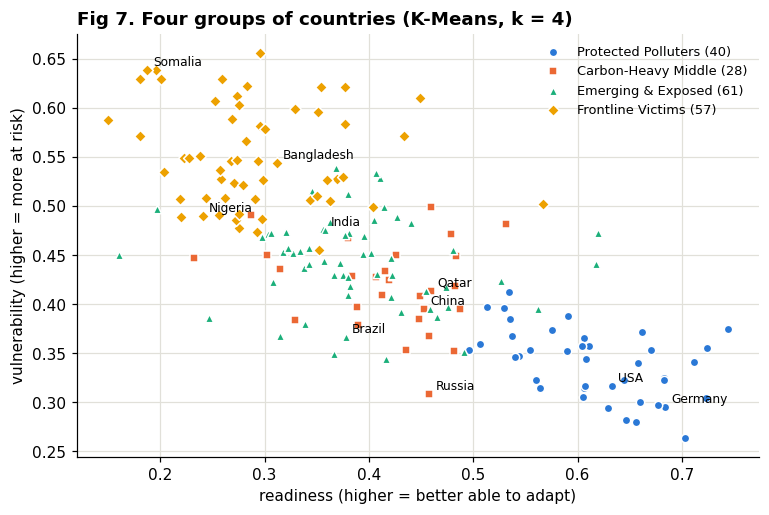

In [20]:
colors, markers = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100'], ['o', 's', '^', 'D']
fig, ax = plt.subplots(figsize=(8, 5))
for i, n in enumerate(NAMES):
    d = df[df.cluster == n]
    ax.scatter(d['readiness'], d['vulnerability'], s=30, color=colors[i], marker=markers[i], edgecolor='white',
               label=f'{n} ({len(d)})')
for iso in ['USA', 'DEU', 'CHN', 'RUS', 'IND', 'BRA', 'NGA', 'SOM', 'BGD', 'QAT']:
    ax.annotate(df.loc[iso, 'country'].replace('United States', 'USA'), (df.loc[iso, 'readiness'], df.loc[iso, 'vulnerability']),
                xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set(title='Fig 7. Four groups of countries (K-Means, k = 4)',
       xlabel='readiness (higher = better able to adapt)', ylabel='vulnerability (higher = more at risk)')
ax.legend(fontsize=8.5)
save(fig, 'fig7_clusters'); plt.show()

**Takeaway:** *Protected Polluters* (USA, Japan, Germany…) are low-risk and highly ready, and hold a big share of historical emissions.
*Frontline Victims* (Pakistan, Nigeria, Bangladesh…) are high-risk, not ready, and emitted very little.

## Chapter 8 — The prediction: can emissions alone spot a climate victim?
A **decision tree** is trained using **only emission data** (log emissions per person, log historical emissions per person,
growth since 2000). It never sees vulnerability or readiness. Each split is chosen to give the biggest **Gini gain**:

Gini index G = 1 − Σ pᵢ²  Gini gain = G(parent) − Σ (nⱼ/n)·G(childⱼ)

Data: 70 % for training, 30 % for testing.

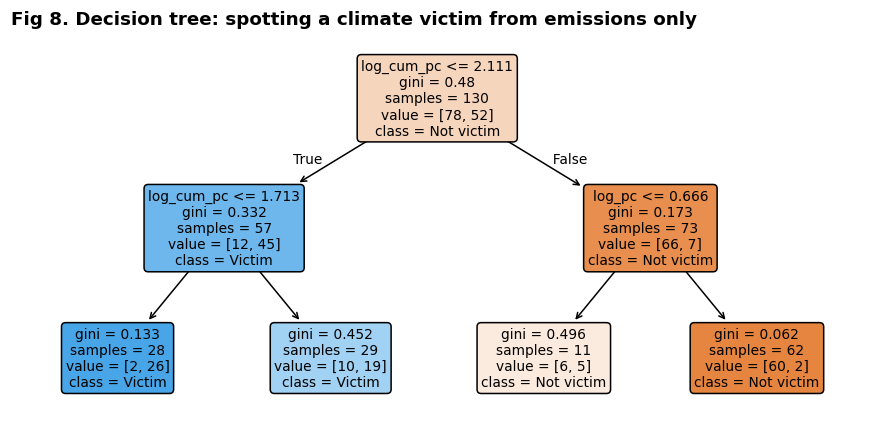

In [21]:
CFEATS = ['log_pc', 'log_cum_pc', 'growth']
X_train, X_test, y_train, y_test = train_test_split(df[CFEATS], df['victim'], test_size=0.3,
                                                    stratify=df['victim'], random_state=42)
tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=42).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(10, 4.6))
plot_tree(tree, feature_names=CFEATS, class_names=['Not victim', 'Victim'], filled=True, rounded=True,
          impurity=True, fontsize=9, ax=ax)
ax.set_title('Fig 8. Decision tree: spotting a climate victim from emissions only', loc='left', fontweight='bold')
save(fig, 'fig8_tree'); plt.show()

In [22]:
# Check the first split by hand with the Gini formulas
t = tree.tree_
counts = [t.value[i][0] / t.value[i][0].sum() * t.n_node_samples[i] for i in range(t.node_count)]   # class counts per node
gini = lambda c: 1 - ((c / c.sum()) ** 2).sum()
root, left, right = counts[0], counts[t.children_left[0]], counts[t.children_right[0]]
gain = gini(root) - left.sum() / root.sum() * gini(left) - right.sum() / root.sum() * gini(right)
print('root', root.round(), 'left', left.round(), 'right', right.round())
print(f"G(root) = {gini(root):.4f}, G(left) = {gini(left):.4f}, G(right) = {gini(right):.4f}, Gini gain = {gain:.4f}")
print(f"Root rule: historical emissions per person <= {10 ** t.threshold[0]:.0f} t")

RESULTS['gini_calc'] = {'root': root.round().tolist(), 'left': left.round().tolist(), 'right': right.round().tolist(),
                        'g_root': gini(root), 'g_left': gini(left), 'g_right': gini(right), 'gain': gain}
RESULTS['tree_nodes'] = [(CFEATS[f] if f >= 0 else 'leaf', round(10 ** th, 1) if f in (0, 1) else round(th, 2),
                          (t.value[i][0] / t.value[i][0].sum()).round(2).tolist(), int(t.n_node_samples[i]))
                         for i, (f, th) in enumerate(zip(t.feature, t.threshold))]

root [78. 52.] left [12. 45.] right [66.  7.]
G(root) = 0.4800, G(left) = 0.3324, G(right) = 0.1734, Gini gain = 0.2369
Root rule: historical emissions per person <= 129 t


In [23]:
pred = tree.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
accuracy  = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall    = tp / (tp + fn)
f1        = 2 * precision * recall / (precision + recall)
baseline  = max(y_test.mean(), 1 - y_test.mean())          # always guessing the bigger class
RESULTS.update({'cm': [int(tn), int(fp), int(fn), int(tp)], 'accuracy': accuracy, 'precision': precision,
                'recall': recall, 'f1': f1, 'baseline': baseline, 'n_test': len(y_test), 'n_train': len(y_train)})
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"Accuracy {accuracy:.3f} | Precision {precision:.3f} | Recall {recall:.3f} | F1 {f1:.3f} | Baseline {baseline:.3f}")

TN=23 FP=11 FN=3 TP=19
Accuracy 0.750 | Precision 0.633 | Recall 0.864 | F1 0.731 | Baseline 0.607


**Takeaway:** a country whose people emitted very little in the past is very likely to be a climate victim. Using emission
numbers alone, the tree beats simple guessing by a wide margin.

## Chapter 9 — The bill: who owes the climate debt?
**Climate debt = % share of emissions (1970–2023) − % share of world population.** Positive = debtor, negative = creditor.

{'Carbon-Heavy Middle': 11.07, 'Emerging & Exposed': -20.2, 'Frontline Victims': -17.71, 'Protected Polluters': 26.83}


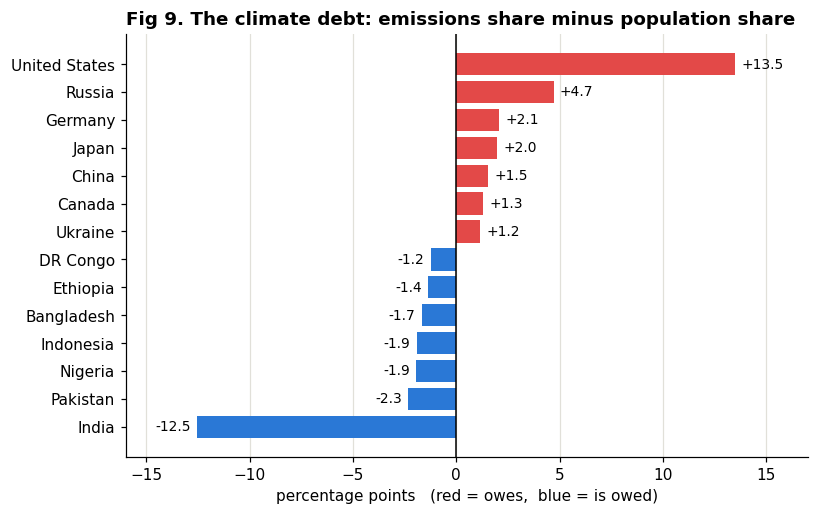

In [24]:
debt = df.sort_values('climate_debt')
show = pd.concat([debt.head(7), debt.tail(7)])
RESULTS['debtors'] = debt.tail(7)[['country', 'climate_debt']].round(2).values.tolist()[::-1]
RESULTS['creditors'] = debt.head(7)[['country', 'climate_debt']].round(2).values.tolist()
RESULTS['cluster_debt'] = df.groupby('cluster')['climate_debt'].sum().round(2).to_dict()
print(RESULTS['cluster_debt'])

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(show['country'], show['climate_debt'], color=['#e34948' if v > 0 else VICT for v in show['climate_debt']])
for yv, v in enumerate(show['climate_debt']):
    ax.text(v + (0.3 if v > 0 else -0.3), yv, f'{v:+.1f}', va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.axvline(0, color='black', lw=1)
ax.set(title='Fig 9. The climate debt: emissions share minus population share', xlim=(-16, 17),
       xlabel='percentage points   (red = owes,  blue = is owed)')
ax.grid(axis='y', visible=False)
save(fig, 'fig9_climate_debt'); plt.show()

## Conclusion
1. A small group of rich countries produced most of the carbon in the sky.
2. The most vulnerable countries produced almost none of it.
3. Emissions and vulnerability are strongly negatively correlated — wealth drives both.
4. Rich and poor countries barely overlap in vulnerability; no rich country is a climate victim.
5. K-Means finds four clear groups, from *Protected Polluters* to *Frontline Victims*.
6. Emission history alone predicts who is a victim, and the climate-debt index shows who owes whom.

**Limitations:** emissions are counted where they are produced (not where goods are consumed); data start in 1970;
land-use emissions are not included; correlation does not prove causation.

In [25]:
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, np.generic): return o.item()
    return o
json.dump(to_py(RESULTS), open('results.json', 'w'), indent=1)
print('saved results.json')

saved results.json
